# Determinanti del PUN e Merit Order Effect in Italia (2016-2025)

Analisi econometrica dei fattori che hanno guidato il **Prezzo Unico Nazionale (PUN)** dell'energia elettrica, su dati mensili dal 2016 al novembre 2025. Obiettivi:

1. stimare l'elasticità del PUN al **costo marginale della generazione a gas** (gas + permessi CO2);
2. stimare l'elasticità al **carico residuo** (domanda non coperta da solare ed eolico) e quindi il *Merit Order Effect* delle rinnovabili non programmabili (VRE);
3. tradurre l'elasticità in un **valore monetario** con un'analisi controfattuale;
4. verificare se sia possibile distinguere il contributo di **solare** ed **eolico**;
5. verificare se i risultati reggono quando si allentano le ipotesi principali: parametri della centrale a gas, elasticità costante nel tempo, prezzo del gas di riferimento, esogeneità della domanda.

Il codice di supporto è nel pacchetto [`src/`](src/): `dati.py` costruisce il dataset mensile dalle fonti originali, `modelli.py` contiene trasformazioni, stime e test.

## 1. Impostazione metodologica

Il modello è una regressione lineare stimata con **OLS**, con errori standard **Newey-West (HAC)** robusti a eteroschedasticità e autocorrelazione. Si usano 4 ritardi, come indica la regola $\lfloor 4\,(T/100)^{2/9} \rfloor$ con $T = 109$.

Le variabili continue entrano in **log-differenze** ($\Delta \ln X_t$):

* per quasi tutte le serie in log-livelli il test ADF non rifiuta la radice unitaria (sezione 4), quindi una regressione in livelli rischierebbe di essere spuria;
* in un modello log-log i coefficienti si leggono come **elasticità**: variazione percentuale del PUN per una variazione dell'1% del regressore.

Le **dummy mensili** (M_2 … M_12) assorbono la stagionalità deterministica.

**Prezzo del gas.** Il modello principale usa il prezzo **spot** del gas al **PSV** (Punto di Scambio Virtuale) sui mercati del GME: è il prezzo pagato dalle centrali italiane e, come il PUN, si riferisce al giorno di consegna. La serie GME parte da ottobre 2016, quindi le stime usano le variazioni da **novembre 2016 a novembre 2025** ($T = 109$). Il TTF olandese della World Bank serve per il confronto (sezione 10.3): è un prezzo vicino al contratto del mese successivo e spiega il PUN peggio del PSV.

**Idroelettrico.** La produzione idroelettrica sposta l'offerta di energia ed è molto variabile da un anno all'altro (siccità del 2022). Entra come **variabile di controllo**. Il suo coefficiente non va interpretato in senso causale, perché gli impianti a bacino scelgono quando produrre anche in base al prezzo.

### Variabili

| Variabile | Descrizione | Unità | Fonte |
|---|---|---|---|
| `PUN` | Prezzo Unico Nazionale, media mensile dei prezzi orari MGP | €/MWh | GME |
| `Ore` | Ore del mese (servono per le medie annue ponderate) | h | GME |
| `Demand` | Domanda elettrica (produzione + saldo estero) | TWh | Ember |
| `Solar`, `Wind`, `Hydro` | Generazione solare, eolica e idroelettrica | TWh | Ember |
| `VRE` | Solare + eolico | TWh | calcolata |
| `Residual_Load` | Domanda − (solare + eolico) | TWh | calcolata |
| `VRE_Share` | (Solare + eolico) / domanda | % | calcolata |
| `Gas_PSV` | Gas naturale al PSV, prezzo spot (da ottobre 2016) | €/MWh | GME |
| `Gas_TTF` | Gas naturale al TTF, vicino al front-month (confronto) | €/MWh | World Bank (Pink Sheet) |
| `CO2_EUA` | Permessi di emissione EU ETS, prezzo d'asta | €/tCO2 | EEX |
| `MC_CCGT_PSV`, `MC_CCGT_TTF` | Costo marginale (combustibile + CO2) di una centrale a ciclo combinato | €/MWh | calcolata |
| `HDD`, `CDD` | Gradi-giorno di riscaldamento e di raffrescamento | numero | Eurostat |
| `Giorni_lavorativi` | Giorni dal lunedì al venerdì, escluse le festività nazionali | giorni | calcolata |

Il costo marginale di una CCGT è approssimato con due **parametri tecnici ipotizzati**, rendimento $\eta = 0.55$ e fattore di emissione $EF = 0.37\ tCO_2$ per MWh elettrico:

$$MC_{CCGT} = \frac{P_{gas}}{\eta} + EF \cdot P_{CO_2}$$

Il rendimento $\eta$ incide solo sul livello di $MC_{CCGT}$, non sulle stime: in log-differenze un fattore di scala costante si annulla. Conta invece il peso relativo di CO2 e gas, che la sezione 10.2 verifica stimando gas e CO2 come regressori separati.

Gradi-giorno e giorni lavorativi servono solo come **variabili strumentali** per la domanda (sezione 10.4).

## 2. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

from src import config as cfg
from src import dati
from src import grafici as g
from src import modelli as m

g.imposta_stile()
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 120)


def p_fmt(p):
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"

## 3. Dati

Il notebook legge il dataset mensile `dati/elaborati/dataset_mensile.csv` (gennaio 2016 – novembre 2025). Il file **non è distribuito** con il repository, perché le condizioni d'uso di alcune fonti (GME, EEX) non ne consentono la ridistribuzione. Si ricostruisce dalle fonti originali con:

```bash
python -m src.dati
```

Le istruzioni per scaricare i file sono in [`dati/README.md`](dati/README.md).

Scelte di costruzione, nessuna delle quali comporta imputazioni:

* **PUN**: media dei prezzi orari. Dal 2025 il GME pubblica il *PUN Index GME*; per il 2025 si usa il file orario (`_60`), che dà le stesse medie mensili del file a 15 minuti.
* **Ember**: lo stesso indicatore compare in più unità (TWh, % del mix, MtCO2e); si tengono solo le righe in **TWh**.
* **Gas PSV**: media mensile del prezzo medio ponderato giornaliero dei mercati a pronti del gas del GME. Parte da ottobre 2016, perché prima il mercato del giorno prima del gas non registra scambi; nel dataset i mesi precedenti sono vuoti. I due giorni senza scambi (8 e 9 ottobre 2016) sono esclusi dalla media del mese.
* **Gas TTF**: colonna *Natural gas, Europe* della World Bank, che secondo le note della World Bank è il prezzo TTF (Netherlands Title Transfer Facility) dall'aprile 2015. È convertita da USD/MMBtu in €/MWh con il cambio medio mensile EUR/USD.
* **CO2**: media semplice mensile dei prezzi di aggiudicazione delle aste primarie EUA su EEX, esclusi i permessi del trasporto aereo. Ogni mese del campione ha almeno un'asta.
* **Gradi-giorno**: tabella Eurostat `nrg_chdd_m`, Italia. **Giorni lavorativi**: lunedì-venerdì meno le festività nazionali, Pasquetta compresa.

In [2]:
df_raw = dati.carica_dataset()
print(f"Periodo: {df_raw.index.min():%Y-%m} - {df_raw.index.max():%Y-%m} ({len(df_raw)} mesi)")
print("Colonne:", ", ".join(df_raw.columns))

Periodo: 2016-01 - 2025-11 (119 mesi)
Colonne: PUN, Ore, Demand, Solar, Wind, Hydro, Gas_PSV, Gas_TTF, CO2_EUA, HDD, CDD, Giorni_lavorativi, VRE, Residual_Load, VRE_Share, MC_CCGT_PSV, MC_CCGT_TTF


In [3]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
PUN,119.0,102.82,86.48,21.79,49.47,67.71,116.89,543.15
Ore,119.0,730.49,19.43,672.00,720.00,743.00,744.00,745.00
Demand,119.0,25.53,1.81,19.17,24.46,25.36,26.32,30.88
Solar,119.0,2.32,1.08,0.74,1.50,2.28,2.92,5.66
Wind,119.0,1.66,0.52,0.71,1.25,1.61,2.00,2.98
Hydro,119.0,3.57,1.19,1.51,2.66,3.40,4.38,6.54
Gas_PSV,110.0,39.27,37.12,6.30,18.40,27.39,42.10,232.60
Gas_TTF,119.0,37.03,38.95,4.94,15.62,23.88,37.62,235.94
CO2_EUA,119.0,42.79,30.21,4.28,15.67,29.76,70.73,91.98
HDD,119.0,153.09,137.26,2.59,17.52,125.72,281.53,464.77


### Analisi esplorativa

Correlazione PUN - MC_CCGT (livelli, da 10/2016): 0.997
Mesi con PUN sopra il costo marginale stimato: 109 su 110
Scarto medio PUN - MC_CCGT: 19.7 €/MWh


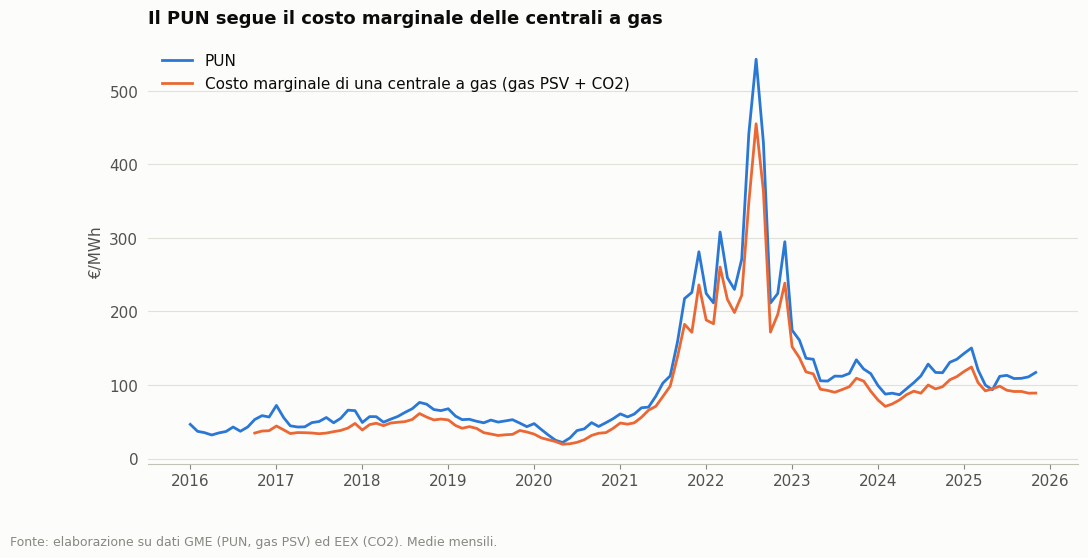

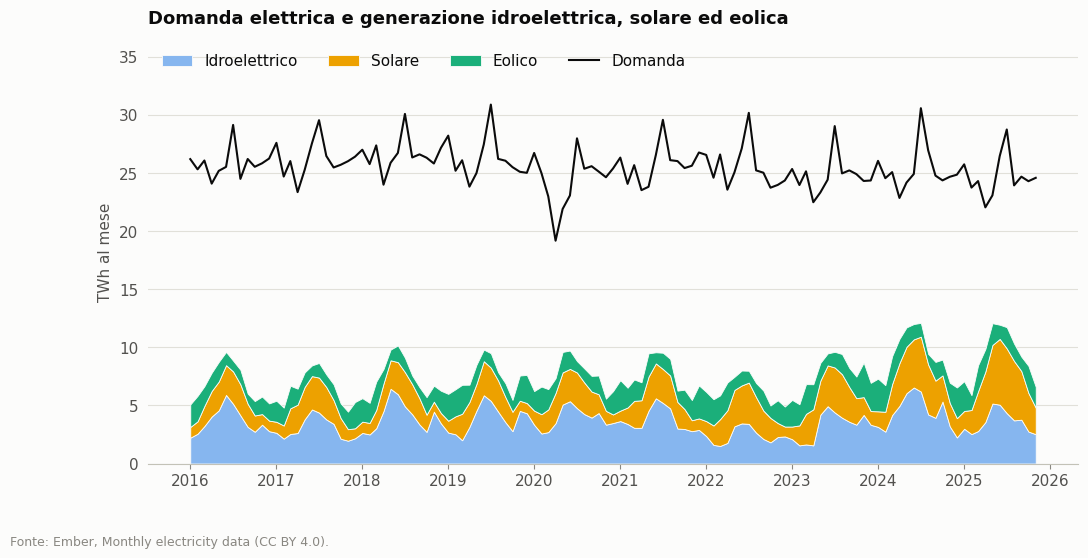

In [4]:
con_psv = df_raw.dropna(subset=["MC_CCGT_PSV"])
scarto = con_psv["PUN"] - con_psv["MC_CCGT_PSV"]
print(f"Correlazione PUN - MC_CCGT (livelli, da 10/2016): {con_psv['PUN'].corr(con_psv['MC_CCGT_PSV']):.3f}")
print(f"Mesi con PUN sopra il costo marginale stimato: {(scarto > 0).sum()} su {len(scarto)}")
print(f"Scarto medio PUN - MC_CCGT: {scarto.mean():.1f} €/MWh")

fig, ax = plt.subplots()
ax.plot(df_raw.index, df_raw["PUN"], color=g.BLU, label="PUN")
ax.plot(df_raw.index, df_raw["MC_CCGT_PSV"], color=g.ARANCIO, label="Costo marginale di una centrale a gas (gas PSV + CO2)")
ax.set_ylabel("€/MWh")
ax.set_title("Il PUN segue il costo marginale delle centrali a gas")
ax.legend(loc="upper left")
g.fonte(fig, "elaborazione su dati GME (PUN, gas PSV) ed EEX (CO2). Medie mensili.")
g.salva(fig, "pun_costo_marginale.png")
plt.show()

fig, ax = plt.subplots()
ax.stackplot(df_raw.index, df_raw["Hydro"], df_raw["Solar"], df_raw["Wind"],
             labels=["Idroelettrico", "Solare", "Eolico"], colors=[g.AZZURRO, g.GIALLO, g.VERDE],
             edgecolor=g.SFONDO, linewidth=0.6)
ax.plot(df_raw.index, df_raw["Demand"], color=g.TESTO, lw=1.5, label="Domanda")
ax.set_ylabel("TWh al mese")
ax.set_title("Domanda elettrica e generazione idroelettrica, solare ed eolica")
ax.set_ylim(0, df_raw["Demand"].max() * 1.18)
ax.legend(loc="upper left", ncols=4)
g.fonte(fig, "Ember, Monthly electricity data (CC BY 4.0).")
plt.show()

Il PUN segue da vicino il costo marginale stimato della CCGT. È coerente con il ruolo del gas come tecnologia che fissa il prezzo nella maggior parte delle ore. La correlazione in livelli va però letta con cautela, perché le due serie condividono trend e shock comuni.

Il PUN resta quasi sempre **sopra** il costo marginale stimato (vedi output). La formula è infatti una semplificazione: usa parametri tecnici fissi e non include altri costi variabili. Inoltre, nelle ore di punta il prezzo può essere fissato da impianti meno efficienti della CCGT di riferimento.

Il secondo grafico mostra anche il crollo della produzione idroelettrica nel 2022, l'anno della siccità.

## 4. Trasformazioni e stazionarietà (test ADF)

Si calcolano log-livelli e log-differenze e si aggiungono le dummy mensili. Il campione di stima parte da novembre 2016 (primo mese con la variazione del prezzo PSV). Il test Augmented Dickey-Fuller ha come ipotesi nulla la presenza di una radice unitaria:

* i **log-livelli** sono testati con costante e trend lineare, perché diverse serie hanno un trend (per esempio il solare);
* le **log-differenze** sono testate con la sola costante.

Il numero di ritardi è scelto con il criterio AIC.

In [5]:
df = m.prepara_variabili(df_raw)      # gas al PSV: variazioni da novembre 2016
print(f"Campione di stima: {df.index.min():%m/%Y} - {df.index.max():%m/%Y} ({len(df)} mesi)")

livelli = ["PUN", "MC_CCGT", "Residual_Load", "Demand", "Solar", "Wind", "Hydro"]
pd.concat([
    m.test_adf(df, [f"log_{c}" for c in livelli], regression="ct"),
    m.test_adf(df, [f"dlog_{c}" for c in livelli], regression="c"),
])

Campione di stima: 11/2016 - 11/2025 (109 mesi)


,Specificazione,ADF,p-value,Lag,Esito (5%)
Variabile,,,,,
log_PUN,costante + trend,-1.991,0.6061,1,Radice unitaria non rifiutata
log_MC_CCGT,costante + trend,-3.225,0.0794,11,Radice unitaria non rifiutata
log_Residual_Load,costante + trend,-2.719,0.2281,13,Radice unitaria non rifiutata
log_Demand,costante + trend,-2.563,0.2970,12,Radice unitaria non rifiutata
log_Solar,costante + trend,0.260,0.9961,12,Radice unitaria non rifiutata
log_Wind,costante + trend,-9.335,0.0000,5,Stazionaria
log_Hydro,costante + trend,-2.184,0.4988,12,Radice unitaria non rifiutata
dlog_PUN,costante,-7.851,0.0000,1,Stazionaria
dlog_MC_CCGT,costante,-5.186,0.0000,2,Stazionaria


In [6]:
# dlog_Hydro: la stagionalità molto marcata porta l'AIC a scegliere molti ritardi.
# Verifica con il criterio BIC e dopo aver tolto le medie mensili (le dummy del modello).
h = df["dlog_Hydro"]
destag = sm.OLS(h, sm.add_constant(df[m.dummy_mensili(df)])).fit().resid
for nome, serie, criterio in [("AIC", h, "AIC"), ("BIC", h, "BIC"), ("AIC, senza medie mensili", destag, "AIC")]:
    stat, p, lag, *_ = adfuller(serie, regression="c", autolag=criterio)
    print(f"ADF dlog_Hydro ({nome}): ritardi {lag:2d}, p-value {p:.4f}")

ADF dlog_Hydro (AIC): ritardi 13, p-value 0.1926
ADF dlog_Hydro (BIC): ritardi  8, p-value 0.0000
ADF dlog_Hydro (AIC, senza medie mensili): ritardi  1, p-value 0.0000


Per i log-livelli di PUN, costo marginale, carico residuo, domanda, solare e idroelettrico il test **non rifiuta** la radice unitaria. L'eolico invece risulta stazionario attorno a un trend.

Le log-differenze rifiutano la radice unitaria per tutte le variabili tranne l'idroelettrico. Per quest'ultimo il risultato dipende dai 13 ritardi scelti dall'AIC per assorbire la forte stagionalità: con il criterio BIC, o dopo aver tolto le medie mensili che il modello comunque include, il test rifiuta nettamente.

Il modello usa le log-differenze per tutte le variabili, eolico compreso: la differenziazione di una serie già stazionaria resta stazionaria, e così tutti i coefficienti si leggono allo stesso modo, come elasticità.

## 5. Correlazioni

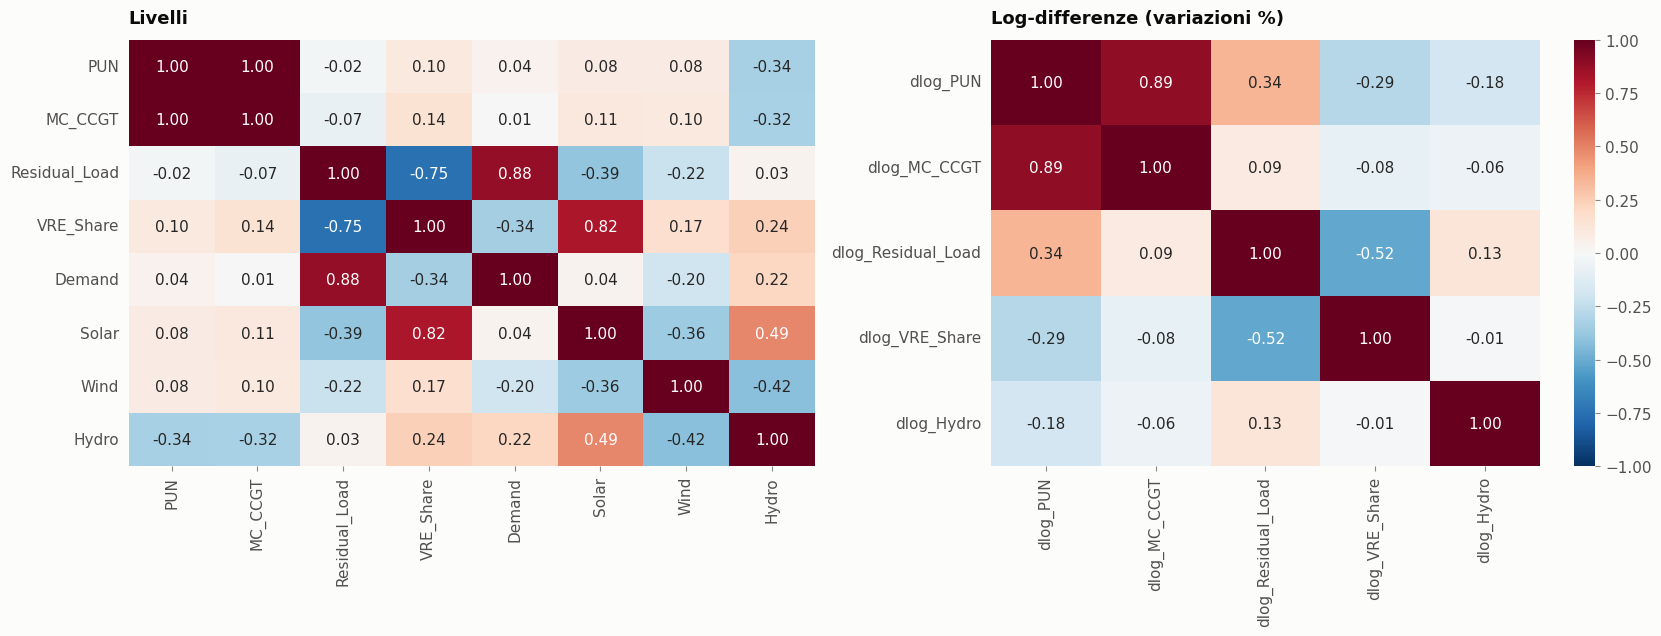

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5))
livelli_corr = ["PUN", "MC_CCGT", "Residual_Load", "VRE_Share", "Demand", "Solar", "Wind", "Hydro"]
sns.heatmap(df[livelli_corr].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax1, cbar=False)
ax1.set_title("Livelli")
dcols = [f"dlog_{c}" for c in ["PUN", "MC_CCGT", "Residual_Load", "VRE_Share", "Hydro"]]
sns.heatmap(df[dcols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax2)
ax2.set_title("Log-differenze (variazioni %)")
for a in (ax1, ax2):
    a.grid(False)
plt.tight_layout()
plt.show()

In livelli le correlazioni riflettono soprattutto trend comuni e lo shock del 2022. In log-differenze il PUN è correlato positivamente con il costo marginale e con il carico residuo, e negativamente con la quota di VRE e con l'idroelettrico, come atteso.

## 6. Modello base: costo marginale e carico residuo

$$\Delta \ln PUN_t = \beta_0 + \beta_1\, \Delta \ln MC^{CCGT}_t + \beta_2\, \Delta \ln RL_t + \beta_3\, \Delta \ln Hydro_t + \sum_{k=2}^{12} \gamma_k M_{k,t} + \varepsilon_t$$

* $\beta_1$ è l'elasticità del PUN al costo del combustibile e della CO2;
* $\beta_2$ è l'elasticità del PUN al carico residuo. Un valore positivo significa che, a parità di domanda, più VRE (quindi meno carico residuo) riducono il prezzo: è il *Merit Order Effect*;
* $\beta_3$ controlla per la produzione idroelettrica.

In [8]:
regressori_base = ["dlog_MC_CCGT", "dlog_Residual_Load", "dlog_Hydro"]
modello = m.stima_ols_hac(df, "dlog_PUN", regressori_base)
print(modello.summary())

                            OLS Regression Results                            
Dep. Variable:               dlog_PUN   R-squared:                       0.920
Model:                            OLS   Adj. R-squared:                  0.908
Method:                 Least Squares   F-statistic:                     135.3
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           8.84e-56
Time:                        18:54:20   Log-Likelihood:                 176.27
No. Observations:                 109   AIC:                            -322.5
Df Residuals:                      94   BIC:                            -282.2
Df Model:                          14                                         
Covariance Type:                  HAC                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -0.0260      0

In [9]:
beta_mc = modello.params["dlog_MC_CCGT"]
beta_rl = modello.params["dlog_Residual_Load"]
print(f"+1% costo marginale CCGT -> PUN {beta_mc:+.2f}%")
print(f"-1% carico residuo       -> PUN {-beta_rl:+.2f}%")

+1% costo marginale CCGT -> PUN +0.93%
-1% carico residuo       -> PUN -0.76%


## 7. Merit Order Effect: analisi controfattuale (metodo *add-back*)

Lo scenario controfattuale ipotizza che la domanda sia coperta senza solare ed eolico, cioè con $RL = Demand$. Si parte dal **prezzo osservato** e lo si corregge con l'elasticità stimata:

$$PUN^{cf}_t = PUN_t \cdot \left(\frac{Demand_t}{RL_t}\right)^{\hat\beta_2}$$

La differenza $PUN^{cf}_t - PUN_t$ è la riduzione di prezzo attribuita alle VRE, in €/MWh. Moltiplicata per la domanda (TWh) dà il *volume* del Merit Order Effect in milioni di euro, nella definizione di Sensfuß, Ragwitz e Genoese (2008, *Energy Policy*).

**Come leggere il risultato**

* È un effetto **lordo sul prezzo all'ingrosso**: non sottrae il costo degli incentivi alle rinnovabili pagati in bolletta (componente ASOS degli oneri di sistema) e assume che tutta la domanda sia valorizzata al PUN.
* È un **ordine di grandezza**, non una previsione puntuale. L'elasticità è stimata su variazioni mensili di pochi punti percentuali, mentre lo scenario rimuove tutte le VRE (la quota media è stampata sotto), e non modella come avrebbero risposto parco termico, importazioni e idroelettrico.
* Per questo il risultato viene riportato anche con gli estremi dell'intervallo di confidenza al 95% di $\hat\beta_2$, e la sezione 7.1 propone due scenari meno estremi.
* È un effetto **di breve periodo**: misura di quanto era più basso il prezzo di ogni mese grazie alla produzione di VRE di quel mese, a parità del resto del sistema. L'effetto di lungo periodo sul livello dei prezzi non è identificato con questi dati (sezione 10.5).
* Il periodo è quello di stima: novembre 2016 – novembre 2025.

In [10]:
cf = m.controfattuale_add_back(df, beta_rl)
lo, hi = modello.conf_int().loc["dlog_Residual_Load"]

righe = {}
for nome, b in [("IC 2,5%", lo), ("Stima puntuale", beta_rl), ("IC 97,5%", hi)]:
    c = m.controfattuale_add_back(df, b)
    righe[nome] = {
        "beta": b,
        "Risparmio medio (€/MWh)": c["Risparmio_EUR_MWh"].mean(),
        "Risparmio totale (mld €)": c["Risparmio_mln_EUR"].sum() / 1000,
    }
sintesi = pd.DataFrame(righe).T.round(2)

print(f"Periodo: {cf.index.min():%m/%Y} - {cf.index.max():%m/%Y} ({len(cf)} mesi)")
print(f"Quota media di VRE sulla domanda: {df['VRE_Share'].mean():.1f}%")
print("Risparmio medio = media semplice dei mesi")
sintesi

Periodo: 11/2016 - 11/2025 (109 mesi)
Quota media di VRE sulla domanda: 15.9%
Risparmio medio = media semplice dei mesi


,beta,Risparmio medio (€/MWh),Risparmio totale (mld €)
"IC 2,5%",0.56,11.43,31.69
Stima puntuale,0.76,16.01,44.36
"IC 97,5%",0.97,20.77,57.55


In [11]:
anni_raw = df_raw.index.year
anni = cf.index.year
annuale = pd.DataFrame({
    "PUN medio annuo (€/MWh)": (df_raw["PUN"] * df_raw["Ore"]).groupby(anni_raw).sum()
                               / df_raw["Ore"].groupby(anni_raw).sum(),
    "Mesi nel controfattuale": cf.groupby(anni).size(),
    "Risparmio medio (€/MWh)": cf["Risparmio_EUR_MWh"].groupby(anni).mean(),
    "Risparmio (mld €)": cf["Risparmio_mln_EUR"].groupby(anni).sum() / 1000,
}).round(2)
annuale

,PUN medio annuo (€/MWh),Mesi nel controfattuale,Risparmio medio (€/MWh),Risparmio (mld €)
Date,,,,
2016,42.78,2,4.41,0.23
2017,53.95,12,6.02,1.89
2018,61.31,12,6.50,2.08
2019,52.32,12,6.31,1.98
2020,38.92,12,4.84,1.42
2021,125.46,12,15.33,4.77
2022,303.95,12,42.76,13.19
2023,127.24,12,20.93,6.20
2024,108.52,12,18.82,5.72


Il PUN medio annuo è ponderato per le ore e coincide con la media annua pubblicata dal GME; per il 2025 copre gennaio-novembre. Il risparmio del 2016 copre solo novembre e dicembre.

Il risparmio è più alto negli anni di prezzi elevati, con il massimo nel 2022. Questo dipende dalla specificazione: con un'elasticità costante, la riduzione in €/MWh è proporzionale al livello del PUN. Non è quindi una prova indipendente che le rinnovabili "valgano di più" quando il gas è caro, ma la conseguenza del modello adottato.

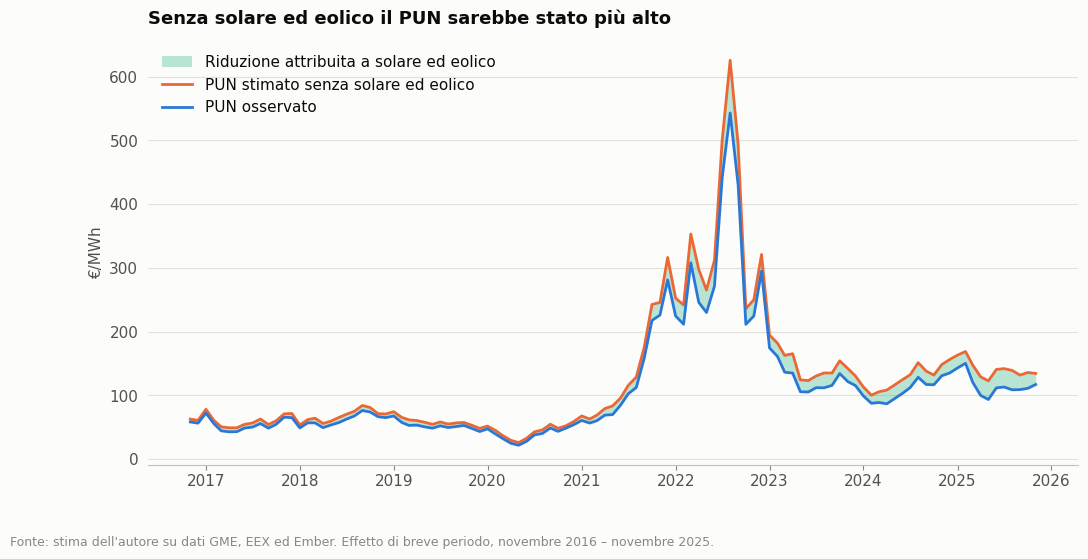

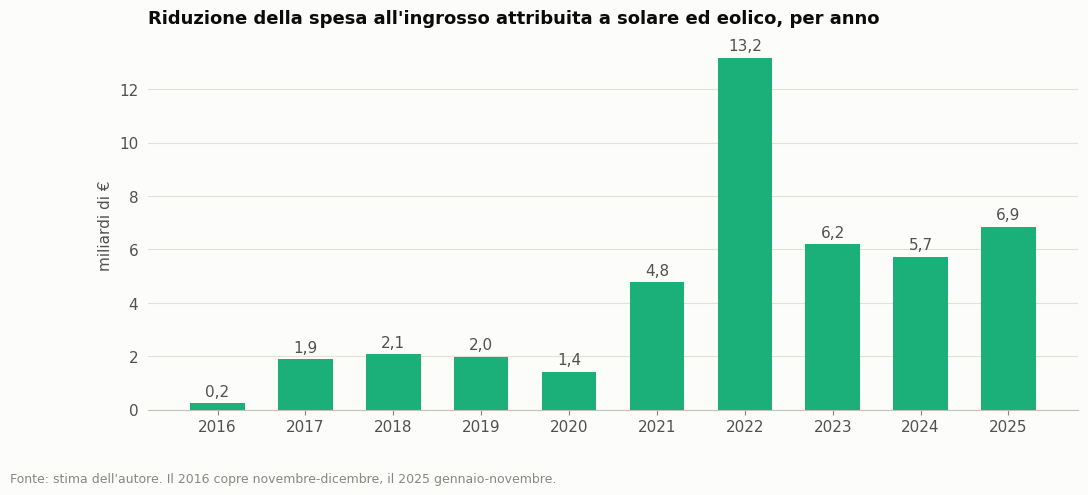

In [12]:
fig, ax = plt.subplots()
ax.fill_between(cf.index, cf["PUN"], cf["PUN_senza_VRE"], color=g.VERDE, alpha=0.30, lw=0,
                label="Riduzione attribuita a solare ed eolico")
ax.plot(cf.index, cf["PUN_senza_VRE"], color=g.ARANCIO, label="PUN stimato senza solare ed eolico")
ax.plot(cf.index, cf["PUN"], color=g.BLU, label="PUN osservato")
ax.set_ylabel("€/MWh")
ax.set_title("Senza solare ed eolico il PUN sarebbe stato più alto")
ax.legend(loc="upper left")
g.fonte(fig, "stima dell'autore su dati GME, EEX ed Ember. Effetto di breve periodo, novembre 2016 – novembre 2025.")
g.salva(fig, "controfattuale_merit_order.png")
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.8))
barre = ax.bar(annuale.index.astype(str), annuale["Risparmio (mld €)"], color=g.VERDE, width=0.62)
ax.bar_label(barre, labels=[f"{v:.1f}".replace(".", ",") for v in annuale["Risparmio (mld €)"]],
             padding=3, color=g.TESTO_SECONDARIO)
ax.set_ylabel("miliardi di €")
ax.set_title("Riduzione della spesa all'ingrosso attribuita a solare ed eolico, per anno")
g.fonte(fig, "stima dell'autore. Il 2016 copre novembre-dicembre, il 2025 gennaio-novembre.")
g.salva(fig, "risparmio_annuo.png")
plt.show()

### 7.1 Scenari alternativi

Lo scenario base ha due punti deboli: usa **un'unica elasticità** per tutto il periodo e porta le VRE **a zero**, molto lontano dai dati osservati. Due scenari alternativi li affrontano:

1. **Elasticità per periodo.** Si stima un modello in cui l'elasticità al carico residuo (e quella al costo marginale) può cambiare dal 2021, interagendo i regressori con una dummy di periodo. Il controfattuale usa poi l'elasticità del rispettivo periodo.
2. **Quota di VRE ferma al 2016.** Invece di eliminare le VRE, si fissa la loro quota sulla domanda al livello dello stesso mese del 2016: $RL^{cf}_t = Demand_t \cdot (1 - quota^{2016}_{m(t)})$ e $PUN^{cf}_t = PUN_t \cdot (RL^{cf}_t / RL_t)^{\hat\beta_2}$. Si misura così l'effetto della sola **crescita** delle rinnovabili dal 2016, con variazioni del carico residuo molto più vicine a quelle usate per stimare l'elasticità.

In [13]:
df["post2021"] = (df.index.year >= 2021).astype(float)
df["dlog_MC_x_post2021"] = df["dlog_MC_CCGT"] * df["post2021"]
df["dlog_RL_x_post2021"] = df["dlog_Residual_Load"] * df["post2021"]
modello_rottura = m.stima_ols_hac(
    df, "dlog_PUN", regressori_base + ["post2021", "dlog_MC_x_post2021", "dlog_RL_x_post2021"]
)
b_rl_pre = modello_rottura.params["dlog_Residual_Load"]
b_rl_post = b_rl_pre + modello_rottura.params["dlog_RL_x_post2021"]
p_rottura = modello_rottura.pvalues["dlog_RL_x_post2021"]
print(f"Elasticità al carico residuo 2016-2020: {b_rl_pre:.3f}")
print(f"Elasticità al carico residuo 2021-2025: {b_rl_post:.3f}")
print(f"Test della differenza (H0: elasticità uguale nei due periodi): p {p_fmt(p_rottura)}")

Elasticità al carico residuo 2016-2020: 0.982
Elasticità al carico residuo 2021-2025: 0.698
Test della differenza (H0: elasticità uguale nei due periodi): p < 0.001


In [14]:
beta_periodo = pd.Series(np.where(df.index.year >= 2021, b_rl_post, b_rl_pre), index=df.index)
rl_2016 = m.carico_residuo_quota_fissa(df, df_raw, anno=2016)

scenari = {
    "Base: VRE = 0, elasticità unica": m.controfattuale_add_back(df, beta_rl),
    "VRE = 0, elasticità per periodo": m.controfattuale_add_back(df, beta_periodo),
    "Quota VRE ferma al 2016": m.controfattuale_add_back(df, beta_rl, rl_cf=rl_2016),
}
tab_scenari = pd.DataFrame({
    nome: {
        "Risparmio medio (€/MWh)": c["Risparmio_EUR_MWh"].mean(),
        "Risparmio totale (mld €)": c["Risparmio_mln_EUR"].sum() / 1000,
    }
    for nome, c in scenari.items()
}).T.round(2)
tab_scenari

,Risparmio medio (€/MWh),Risparmio totale (mld €)
"Base: VRE = 0, elasticità unica",16.01,44.36
"VRE = 0, elasticità per periodo",15.59,43.27
Quota VRE ferma al 2016,3.85,10.55


In [15]:
quota_annua = 100 * df_raw["VRE"].groupby(anni_raw).sum() / df_raw["Demand"].groupby(anni_raw).sum()
pd.concat(
    [quota_annua.rename("Quota VRE (%)")]
    + [c["Risparmio_mln_EUR"].groupby(anni).sum().div(1000).rename(f"{nome} (mld €)") for nome, c in scenari.items()],
    axis=1,
).round(2)

,Quota VRE (%),"Base: VRE = 0, elasticità unica (mld €)","VRE = 0, elasticità per periodo (mld €)",Quota VRE ferma al 2016 (mld €)
Date,,,,
2016,12.64,0.23,0.30,-0.00
2017,13.19,1.89,2.47,0.07
2018,12.44,2.08,2.71,-0.03
2019,13.79,1.98,2.59,0.16
2020,14.74,1.42,1.86,0.20
2021,14.66,4.77,4.34,0.83
2022,15.69,13.19,11.98,2.46
2023,18.14,6.20,5.62,1.90
2024,19.00,5.72,5.19,1.95


* L'elasticità al carico residuo è **significativamente più bassa dal 2021** (vedi test sopra). Le stime separate per sotto-periodo della sezione 10.1 danno lo stesso quadro. Usando l'elasticità del rispettivo periodo, il volume cumulato cambia poco rispetto allo scenario base: il risultato principale non dipende dall'ipotesi di elasticità costante.
* Lo scenario con la **quota di VRE ferma al 2016** dà un volume molto più piccolo, concentrato negli anni in cui la quota di VRE è cresciuta di più e i prezzi erano alti. È una misura più prudente perché estrapola molto meno: risponde a una domanda diversa, cioè quanto ha fatto risparmiare la crescita delle rinnovabili dal 2016, non la loro presenza.
* Nel 2016 lo scenario relativo vale zero per costruzione. Nei mesi in cui la quota di VRE è sotto quella dello stesso mese del 2016 il risparmio è negativo.

## 8. Diagnostica del modello base

| Test | Ipotesi nulla |
|---|---|
| VIF | (misura di multicollinearità; regola pratica: problematica sopra 5-10) |
| Durbin-Watson | assenza di autocorrelazione del primo ordine (valore vicino a 2) |
| Breusch-Godfrey(4) | assenza di autocorrelazione fino al ritardo 4 |
| Ljung-Box(12) | assenza di autocorrelazione fino al ritardo 12 |
| Breusch-Pagan | omoschedasticità |
| Jarque-Bera | normalità dei residui |

In [16]:
display(m.tabella_vif(modello).T)
m.diagnostica(modello)

,dlog_MC_CCGT,dlog_Residual_Load,dlog_Hydro,M_2,M_3,M_4,M_5,M_6,M_7,M_8,M_9,M_10,M_11,M_12
VIF,1.16,5.04,2.05,2.54,1.98,3.29,2.52,2.06,2.38,3.54,1.97,1.91,2.03,1.97


Durbin-Watson                   2.2047
Breusch-Godfrey(4) p-value      0.0060
Ljung-Box(12) p-value           0.1272
Breusch-Pagan p-value           0.4796
Jarque-Bera p-value             0.0078
R2                              0.9202
R2 corretto                     0.9083
Osservazioni                  109.0000
dtype: float64

**Lettura dei risultati** (p-value nella tabella sopra):

* il VIF più alto è quello del carico residuo, circa 5: al limite della soglia prudenziale, ma lontano da 10. Deriva dalla stagionalità del carico residuo, che le dummy mensili catturano in gran parte; il coefficiente resta comunque stimato con precisione;
* il Durbin-Watson è vicino a 2, ma il Breusch-Godfrey rifiuta l'assenza di autocorrelazione fino al ritardo 4; il Ljung-Box fino al ritardo 12 non la rifiuta;
* il Breusch-Pagan non rifiuta l'omoschedasticità;
* il Jarque-Bera rifiuta la normalità: i residui hanno code spesse, dovute agli shock di prezzo.

L'autocorrelazione giustifica gli errori standard HAC; la sezione 10.1 ripete la stima con 8 e 12 ritardi. Con residui non normali l'inferenza si basa su risultati asintotici, da tenere presenti con 109 osservazioni.

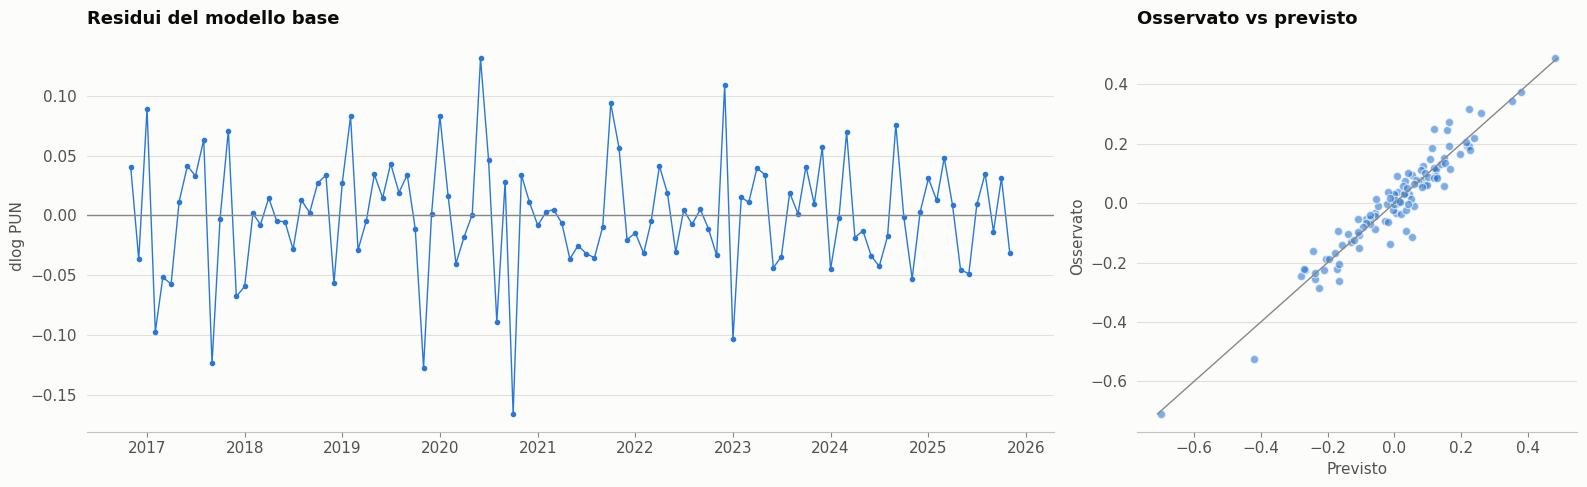

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.2, 1]})
ax1.plot(df.index, modello.resid, color=g.BLU, lw=1, marker="o", ms=3)
ax1.axhline(0, color=g.GRIGIO, lw=1)
ax1.set_title("Residui del modello base")
ax1.set_ylabel("dlog PUN")
ax2.scatter(modello.fittedvalues, df["dlog_PUN"], alpha=0.6, color=g.BLU, edgecolor=g.SFONDO)
lim = [df["dlog_PUN"].min(), df["dlog_PUN"].max()]
ax2.plot(lim, lim, color=g.GRIGIO, lw=1)
ax2.set_xlabel("Previsto")
ax2.set_ylabel("Osservato")
ax2.set_title("Osservato vs previsto")
plt.tight_layout()
plt.show()

## 9. Solare ed eolico

### 9.1 Scomposizione del carico residuo

$$\Delta \ln PUN_t = \beta_0 + \beta_1 \Delta \ln MC^{CCGT}_t + \beta_2 \Delta \ln Demand_t + \beta_3 \Delta \ln Solar_t + \beta_4 \Delta \ln Wind_t + \beta_5 \Delta \ln Hydro_t + \sum_k \gamma_k M_{k,t} + \varepsilon_t$$

In [18]:
modello_dec = m.stima_ols_hac(df, "dlog_PUN", ["dlog_MC_CCGT", "dlog_Demand", "dlog_Solar", "dlog_Wind", "dlog_Hydro"])
print(modello_dec.summary())

                            OLS Regression Results                            
Dep. Variable:               dlog_PUN   R-squared:                       0.921
Model:                            OLS   Adj. R-squared:                  0.907
Method:                 Least Squares   F-statistic:                     115.0
Date:                Fri, 13 Nov 2026   Prob (F-statistic):           1.66e-53
Time:                        18:54:21   Log-Likelihood:                 176.95
No. Observations:                 109   AIC:                            -319.9
Df Residuals:                      92   BIC:                            -274.2
Df Model:                          16                                         
Covariance Type:                  HAC                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.0122      0.017     -0.730   

,dlog_MC_CCGT,dlog_Demand,dlog_Solar,dlog_Wind,dlog_Hydro,M_2,M_3,M_4,M_5,M_6,M_7,M_8,M_9,M_10,M_11,M_12
VIF,1.25,7.98,6.75,1.34,2.25,3.47,2.57,4.36,2.56,2.12,2.69,5.48,3.09,3.31,4.53,2.52


Quota della variazione spiegata dagli altri regressori (dummy mensili, domanda, ...):
dlog_Solar    0.85
dlog_Wind     0.25

Test congiunto solare = eolico = 0: p-value < 0.001


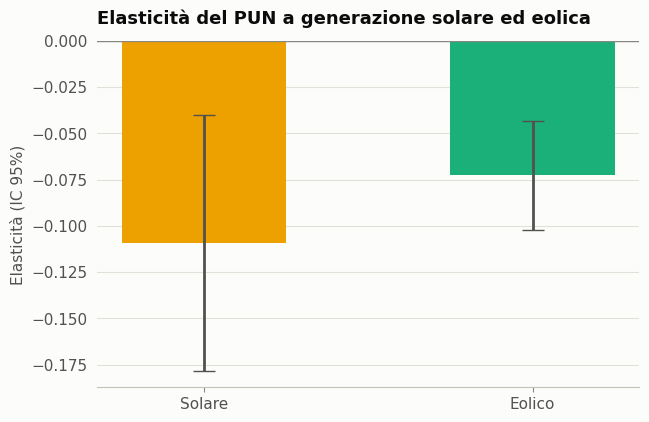

In [19]:
vre = ["dlog_Solar", "dlog_Wind"]
vif_dec = m.tabella_vif(modello_dec)
display(vif_dec.T)

# R^2 della regressione di ciascuna variabile sugli altri regressori = 1 - 1/VIF
quota = (1 - 1 / vif_dec.loc[vre, "VIF"]).round(2)
print("Quota della variazione spiegata dagli altri regressori (dummy mensili, domanda, ...):")
print(quota.to_string())

wald = modello_dec.wald_test("dlog_Solar = 0, dlog_Wind = 0", scalar=True)
print(f"\nTest congiunto solare = eolico = 0: p-value {p_fmt(float(wald.pvalue))}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(["Solare", "Eolico"], modello_dec.params[vre], yerr=1.96 * modello_dec.bse[vre],
       capsize=8, color=[g.GIALLO, g.VERDE], ecolor=g.TESTO_SECONDARIO, width=0.5)
ax.axhline(0, color=g.GRIGIO, lw=1)
ax.set_ylabel("Elasticità (IC 95%)")
ax.set_title("Elasticità del PUN a generazione solare ed eolica")
plt.show()

In [20]:
# Stessa scomposizione con gas TTF e senza idroelettrico
dec_ttf = m.stima_ols_hac(m.prepara_variabili(df_raw, gas="TTF"), "dlog_PUN",
                           ["dlog_MC_CCGT", "dlog_Demand", "dlog_Solar", "dlog_Wind"])
pd.DataFrame({
    "Gas TTF, senza idro": dec_ttf.params[vre].round(3).astype(str) + " (p " + dec_ttf.pvalues[vre].map(lambda p: f"{p:.3f}") + ")",
    "Modello principale (PSV, con idro)": modello_dec.params[vre].round(3).astype(str) + " (p " + modello_dec.pvalues[vre].map(lambda p: f"{p:.3f}") + ")",
})

,"Gas TTF, senza idro","Modello principale (PSV, con idro)"
dlog_Solar,-0.12 (p 0.137),-0.109 (p 0.002)
dlog_Wind,-0.044 (p 0.125),-0.073 (p 0.000)


Entrambi i coefficienti sono **negativi e significativi** anche presi singolarmente, e lo è anche il test congiunto. Con il gas TTF e senza idroelettrico non lo sono (tabella sopra): con il prezzo del gas italiano e il controllo per l'idroelettrico la varianza residua è molto più bassa, e questo basta a separare le due fonti.

La stima del solare resta però **più fragile** di quella dell'eolico. La maggior parte della variazione mensile del solare è già spiegata dagli altri regressori, perché segue un ciclo stagionale molto regolare, catturato in gran parte dalle dummy mensili; il coefficiente è identificato dalla parte residua. All'eolico resta molta più variazione propria (vedi quote stampate sopra).

Le elasticità misurano effetti percentuali e non sono direttamente confrontabili tra le due fonti, che hanno livelli e profili orari diversi. Un'ipotesi, non verificabile con questi dati, è che il solare abbassi soprattutto i prezzi delle ore centrali della giornata e che la media mensile del PUN diluisca questo effetto. Per testarla servirebbero dati orari.

### 9.2 Effetto complessivo delle VRE e coerenza con il controfattuale

Il controfattuale della sezione 7 usa l'elasticità al carico residuo, cioè assume che una variazione delle VRE pesi sul prezzo come una variazione della domanda di pari entità. Per verificarlo si stima un modello con domanda e VRE separate:

$$\Delta \ln PUN_t = \beta_0 + \beta_1 \Delta \ln MC^{CCGT}_t + \beta_2 \Delta \ln Demand_t + \beta_3 \Delta \ln VRE_t + \beta_4 \Delta \ln Hydro_t + \sum_k \gamma_k M_{k,t} + \varepsilon_t$$

Il modello base implica un'elasticità alle VRE di circa $-\hat\beta_{RL} \cdot \overline{VRE/RL}$, approssimata con il valore medio del rapporto.

In [21]:
modello_vre = m.stima_ols_hac(df, "dlog_PUN", ["dlog_MC_CCGT", "dlog_Demand", "dlog_VRE", "dlog_Hydro"])
b_vre = modello_vre.params["dlog_VRE"]
lo_vre, hi_vre = modello_vre.conf_int().loc["dlog_VRE"]
implicita = -beta_rl * (df["VRE"] / df["Residual_Load"]).mean()

print(f"Elasticità alle VRE, stima diretta: {b_vre:.3f} (IC 95%: {lo_vre:.3f} / {hi_vre:.3f}; p {p_fmt(modello_vre.pvalues['dlog_VRE'])})")
print(f"Elasticità alle VRE implicita nel modello base: {implicita:.3f}")

Elasticità alle VRE, stima diretta: -0.198 (IC 95%: -0.261 / -0.135; p < 0.001)
Elasticità alle VRE implicita nel modello base: -0.147


La stima diretta è significativa e un po' più forte di quella implicita nel modello base, che però cade nel suo intervallo di confidenza. Il controfattuale, che usa l'elasticità al carico residuo, è quindi coerente con l'effetto stimato direttamente sulle rinnovabili, e semmai prudente.

## 10. Robustezza

Cinque gruppi di verifiche sul modello base:

1. **sotto-periodi e ritardi HAC** (10.1);
2. **parametri della CCGT**: gas e CO2 stimati come regressori separati, senza imporre $\eta$ ed $EF$ (10.2);
3. **prezzo del gas e idroelettrico**: specificazioni alternative (10.3);
4. **endogeneità della domanda**: stima con variabili strumentali (10.4);
5. **cointegrazione**: modello a correzione dell'errore ed elasticità di lungo periodo (10.5).

### 10.1 Sotto-periodi e ritardi HAC

I sotto-periodi controllano che il risultato non dipenda dalla crisi 2021-2023. Nel campione che esclude il 2021-2023, le osservazioni prima e dopo la crisi sono trattate come consecutive nel calcolo degli errori HAC.

In [22]:
def riepilogo(mod):
    lo_, hi_ = mod.conf_int().loc["dlog_Residual_Load"]
    return {
        "beta MC": round(mod.params["dlog_MC_CCGT"], 3),
        "beta RL": round(mod.params["dlog_Residual_Load"], 3),
        "IC 2,5%": round(lo_, 3),
        "IC 97,5%": round(hi_, 3),
        "p-value RL": f"{mod.pvalues['dlog_Residual_Load']:.1e}",
        "Oss.": int(mod.nobs),
    }


anno = df.index.year
periodi = {
    "Campione completo": np.ones(len(df), dtype=bool),
    "Escluso 2021-2023": (anno < 2021) | (anno > 2023),
    "2016-2020": anno <= 2020,
    "2021-2025": anno >= 2021,
}
pd.DataFrame({k: riepilogo(m.stima_ols_hac(df[v], "dlog_PUN", regressori_base)) for k, v in periodi.items()}).T

,beta MC,beta RL,"IC 2,5%","IC 97,5%",p-value RL,Oss.
Campione completo,0.929,0.764,0.557,0.971,4.6e-13,109
Escluso 2021-2023,0.887,0.698,0.433,0.963,2.4e-07,73
2016-2020,0.882,1.006,0.692,1.32,3.5e-10,50
2021-2025,0.945,0.626,0.474,0.778,6.2e-16,59


In [23]:
# Confronto con il modello con interazione della sezione 7.1
pd.DataFrame({
    "Modello con interazione (7.1)": {"2016-2020": b_rl_pre, "2021-2025": b_rl_post},
    "Stime separate (10.1)": {
        p: m.stima_ols_hac(df[periodi[p]], "dlog_PUN", regressori_base).params["dlog_Residual_Load"]
        for p in ["2016-2020", "2021-2025"]
    },
}).round(3)

,Modello con interazione (7.1),Stime separate (10.1)
2016-2020,0.982,1.006
2021-2025,0.698,0.626


In [24]:
pd.DataFrame({
    f"HAC {L} ritardi": riepilogo(m.stima_ols_hac(df, "dlog_PUN", regressori_base, lags=L))
    for L in (4, 8, 12)
}).T

,beta MC,beta RL,"IC 2,5%","IC 97,5%",p-value RL,Oss.
HAC 4 ritardi,0.929,0.764,0.557,0.971,4.6e-13,109
HAC 8 ritardi,0.929,0.764,0.542,0.986,1.5e-11,109
HAC 12 ritardi,0.929,0.764,0.539,0.989,2.9e-11,109


L'elasticità al carico residuo resta positiva e significativa in tutti i sotto-periodi. La sua entità cambia: è più alta nel 2016-2020 e più bassa nel 2021-2025, quando il prezzo è dominato dallo shock del gas. La differenza è statisticamente significativa (sezione 7.1), e lo scenario con elasticità per periodo ne tiene conto.

Le stime separate differiscono un po' da quelle del modello con interazione della sezione 7.1 (tabella sopra): nel modello con interazione dummy mensili e idroelettrico hanno lo stesso effetto nei due periodi, nelle stime separate no. Il quadro è lo stesso. La significatività non cambia con 8 o 12 ritardi HAC.

### 10.2 Parametri della CCGT: gas e CO2 separati

Il costo marginale si può scrivere come $MC = (P_{gas} + e \cdot P_{CO_2}) / \eta$, dove $e = EF \cdot \eta$ sono le emissioni per MWh di gas bruciato (circa 0,20 tCO2/MWh con i parametri adottati). In log-differenze:

$$\Delta \ln MC_t \approx w_t\, \Delta \ln P^{gas}_t + (1 - w_t)\, \Delta \ln P^{CO_2}_t, \qquad w_t = \frac{P^{gas}_t}{P^{gas}_t + e \cdot P^{CO_2}_t}$$

dove $w_t$ è la quota del gas nel costo marginale. Il modello base impone quindi che gas e CO2 pesino sul PUN nel rapporto $w : (1-w)$. Per verificarlo, si stimano **gas e CO2 come regressori separati**, senza alcun parametro tecnico, e si testa se la quota del gas stimata, $\beta_{gas} / (\beta_{gas} + \beta_{CO_2})$, è compatibile con la quota media osservata $\bar w$. Poiché $w_t$ varia nel tempo, il test è un'approssimazione.

In [25]:
var_sep = ["dlog_Gas", "dlog_CO2_EUA", "dlog_Residual_Load", "dlog_Hydro"]
modello_sep = m.stima_ols_hac(df, "dlog_PUN", var_sep)
ic_sep = modello_sep.conf_int().loc[var_sep]
display(pd.DataFrame({
    "coef": modello_sep.params[var_sep],
    "IC 2,5%": ic_sep[0],
    "IC 97,5%": ic_sep[1],
    "p-value": modello_sep.pvalues[var_sep].map(lambda p: f"{p:.1e}"),
}).round(3))

w_media = (df_raw["Gas_PSV"] / cfg.ETA_CCGT / df_raw["MC_CCGT_PSV"]).mean()
b_gas, b_co2 = modello_sep.params["dlog_Gas"], modello_sep.params["dlog_CO2_EUA"]
quota_stimata = b_gas / (b_gas + b_co2)
test_quota = modello_sep.wald_test(
    f"{1 - w_media:.6f} * dlog_Gas - {w_media:.6f} * dlog_CO2_EUA = 0", scalar=True
)
p_quota = float(test_quota.pvalue)
print(f"Quota del gas: stimata {quota_stimata:.3f}, media osservata {w_media:.3f}; test di uguaglianza p {p_fmt(p_quota)}")
print(f"Somma delle elasticità gas + CO2: {b_gas + b_co2:.3f} (modello base: {beta_mc:.3f})")
print("VIF:", m.tabella_vif(modello_sep).loc[var_sep, "VIF"].to_dict())

,coef,"IC 2,5%","IC 97,5%",p-value
dlog_Gas,0.751,0.660,0.841,2.0e-59
dlog_CO2_EUA,0.211,0.041,0.382,1.5e-02
dlog_Residual_Load,0.778,0.550,1.006,2.1e-11
dlog_Hydro,-0.162,-0.238,-0.087,2.5e-05


Quota del gas: stimata 0.780, media osservata 0.790; test di uguaglianza p = 0.906
Somma delle elasticità gas + CO2: 0.962 (modello base: 0.929)
VIF: {'dlog_Gas': 1.22, 'dlog_CO2_EUA': 1.15, 'dlog_Residual_Load': 5.09, 'dlog_Hydro': 2.05}


La sensibilità che segue fa variare direttamente $e$ tra 0,18 e 0,22 tCO2/MWh: l'intervallo include i valori riferiti al potere calorifico superiore (circa 0,18) e inferiore (circa 0,20) del gas. Si verifica anche che $\eta$ non abbia alcun effetto.

In [26]:
e_base = cfg.EF_CCGT * cfg.ETA_CCGT        # emissioni per MWh di gas implicite nei parametri


def dlog_mc(eta, e):
    mc = (df_raw["Gas_PSV"] + e * df_raw["CO2_EUA"]) / eta
    return np.log(mc).diff().dropna()


print(f"Emissioni per MWh di gas implicite: e = {e_base:.4f} tCO2/MWh")
print("dlog_MC identico con eta = 0.50 e eta = 0.58:", np.allclose(dlog_mc(0.50, e_base), dlog_mc(0.58, e_base)))

sensibilita = {}
for e in (0.18, e_base, 0.22):
    d = df_raw.copy()
    d["MC_CCGT_PSV"] = (d["Gas_PSV"] + e * d["CO2_EUA"]) / cfg.ETA_CCGT
    dd = m.prepara_variabili(d)
    mod = m.stima_ols_hac(dd, "dlog_PUN", regressori_base)
    r = riepilogo(mod)
    r["Risparmio totale (mld €)"] = round(m.controfattuale_add_back(dd, mod.params["dlog_Residual_Load"])["Risparmio_mln_EUR"].sum() / 1000, 2)
    sensibilita[f"e = {e:.3f}"] = r
pd.DataFrame(sensibilita).T

Emissioni per MWh di gas implicite: e = 0.2035 tCO2/MWh
dlog_MC identico con eta = 0.50 e eta = 0.58: True


,beta MC,beta RL,"IC 2,5%","IC 97,5%",p-value RL,Oss.,Risparmio totale (mld €)
e = 0.180,0.914,0.769,0.562,0.976,3.6e-13,109,44.68
e = 0.204,0.929,0.764,0.557,0.971,4.6e-13,109,44.36
e = 0.220,0.94,0.76,0.554,0.967,5.6e-13,109,44.14


Stimati senza restrizioni, gas e CO2 hanno entrambi un effetto positivo e significativo, e la quota del gas stimata è compatibile con quella implicita nei parametri adottati: il test non rifiuta l'uguaglianza. L'elasticità al carico residuo resta vicina a quella del modello base. I parametri $\eta$ ed $EF$ non sono quindi una fonte di distorsione: $\eta$ non ha alcun effetto sulle stime, e il peso della CO2 ($e$) le sposta solo di poco.

### 10.3 Prezzo del gas e idroelettrico: specificazioni alternative

La tabella parte dalla specificazione più semplice, con il gas TTF e senza idroelettrico, e arriva al modello principale un cambiamento alla volta, per mostrare l'effetto di ciascuna scelta:

1. TTF senza idroelettrico, febbraio 2016 – novembre 2025;
2. TTF con idroelettrico, stesso periodo;
3. TTF con idroelettrico, stesso campione del PSV (da novembre 2016);
4. PSV senza idroelettrico;
5. PSV con idroelettrico (modello principale).

Il confronto tra le righe 4 e 5 mostra se il risultato dipende dal controllo per l'idroelettrico, che è in parte endogeno al prezzo (rischio di *bad control*).

Il TTF della World Bank e il PSV del GME differiscono per due motivi: il **mercato** (olandese o italiano) e la **scadenza**. Il TTF della World Bank è vicino al contratto per il mese successivo (*front-month*), mentre il PSV del GME è un prezzo **spot**, come il PUN. Nell'autunno 2022, quando i prezzi a termine erano molto sopra quelli spot, la differenza è stata ampia.

In [27]:
df_ttf = m.prepara_variabili(df_raw, gas="TTF")
regressori_senza_idro = ["dlog_MC_CCGT", "dlog_Residual_Load"]
specifiche = {
    "1. TTF senza idroelettrico, 02/2016 - 11/2025": (df_ttf, regressori_senza_idro),
    "2. TTF con idroelettrico, 02/2016 - 11/2025": (df_ttf, regressori_base),
    "3. TTF con idroelettrico, 11/2016 - 11/2025": (df_ttf.loc[df.index], regressori_base),
    "4. PSV senza idroelettrico, 11/2016 - 11/2025": (df, regressori_senza_idro),
    "5. PSV con idroelettrico, 11/2016 - 11/2025 (principale)": (df, regressori_base),
}
confronto_gas = {}
for nome, (d, reg) in specifiche.items():
    mod = m.stima_ols_hac(d, "dlog_PUN", reg)
    r = riepilogo(mod)
    r["R2"] = round(mod.rsquared, 3)
    r["Risparmio totale (mld €)"] = round(m.controfattuale_add_back(d, mod.params["dlog_Residual_Load"])["Risparmio_mln_EUR"].sum() / 1000, 1)
    confronto_gas[nome] = r
tab_gas = pd.DataFrame(confronto_gas).T
tab_gas

,beta MC,beta RL,"IC 2,5%","IC 97,5%",p-value RL,Oss.,R2,Risparmio totale (mld €)
"1. TTF senza idroelettrico, 02/2016 - 11/2025",0.927,0.863,0.558,1.168,2.9e-08,118,0.8,51.8
"2. TTF con idroelettrico, 02/2016 - 11/2025",0.922,0.863,0.6,1.125,1.2e-10,118,0.825,51.8
"3. TTF con idroelettrico, 11/2016 - 11/2025",0.929,0.88,0.597,1.164,1.2e-09,109,0.823,51.7
"4. PSV senza idroelettrico, 11/2016 - 11/2025",0.928,0.775,0.51,1.04,1.0e-08,109,0.895,45.1
"5. PSV con idroelettrico, 11/2016 - 11/2025 (principale)",0.929,0.764,0.557,0.971,4.6e-13,109,0.92,44.4


In [28]:
# Confronto diretto: entrambi i costi marginali nella stessa regressione
gara = df.copy()
gara["dlog_MC_CCGT_TTF"] = np.log(df_raw["MC_CCGT_TTF"]).diff().loc[gara.index]
modello_gara = m.stima_ols_hac(gara, "dlog_PUN", ["dlog_MC_CCGT", "dlog_MC_CCGT_TTF", "dlog_Residual_Load", "dlog_Hydro"])
for v, nome in [("dlog_MC_CCGT", "costo marginale con PSV"), ("dlog_MC_CCGT_TTF", "costo marginale con TTF")]:
    print(f"Elasticità al {nome}: {modello_gara.params[v]:+.3f} (p {p_fmt(modello_gara.pvalues[v])})")
print(f"Correlazione PSV - TTF (livelli, da 10/2016): {df_raw['Gas_PSV'].corr(df_raw['Gas_TTF']):.3f}")

Elasticità al costo marginale con PSV: +0.953 (p < 0.001)
Elasticità al costo marginale con TTF: -0.028 (p = 0.667)
Correlazione PSV - TTF (livelli, da 10/2016): 0.988


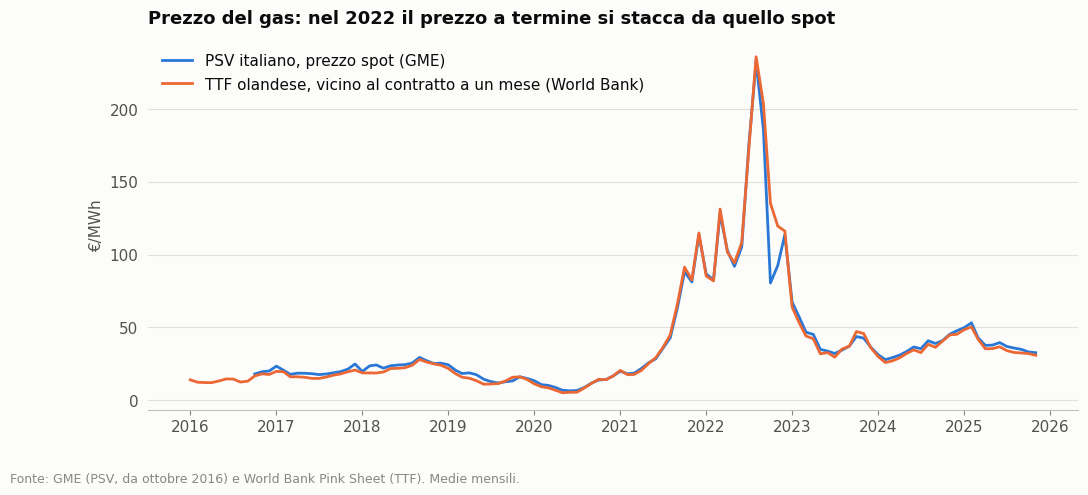

In [29]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(df_raw.index, df_raw["Gas_PSV"], color=g.BLU, label="PSV italiano, prezzo spot (GME)")
ax.plot(df_raw.index, df_raw["Gas_TTF"], color=g.ARANCIO, label="TTF olandese, vicino al contratto a un mese (World Bank)")
ax.set_ylabel("€/MWh")
ax.set_title("Prezzo del gas: nel 2022 il prezzo a termine si stacca da quello spot")
ax.legend(loc="upper left")
g.fonte(fig, "GME (PSV, da ottobre 2016) e World Bank Pink Sheet (TTF). Medie mensili.")
g.salva(fig, "gas_psv_ttf.png")
plt.show()

* Aggiungere l'**idroelettrico** (riga 2) non cambia l'elasticità al carico residuo, ma aumenta la quota di variabilità spiegata e restringe l'intervallo di confidenza.
* Restringere il **campione** a novembre 2016 (riga 3) cambia poco.
* La differenza viene dal **prezzo del gas** (righe 4 e 5): con il PSV l'R² sale nettamente e l'elasticità al carico residuo scende, insieme al volume del controfattuale. Gli intervalli di confidenza delle righe 3 e 5 si sovrappongono ampiamente.
* Con il PSV, togliere l'idroelettrico (riga 4 contro riga 5) lascia l'elasticità al carico residuo e il volume praticamente invariati: il risultato **non dipende** dal controllo per l'idroelettrico, quindi il rischio di *bad control* non tocca la stima principale.
* Messi nella stessa regressione, il costo marginale calcolato con il PSV assorbe tutto l'effetto e quello calcolato con il TTF non aggiunge nulla: il PSV spot è la misura giusta del costo del gas per il PUN.

### 10.4 Endogeneità della domanda: variabili strumentali

La domanda può reagire al prezzo: nel 2022 i prezzi alti l'hanno ridotta. In questo caso uno shock positivo del prezzo abbassa la domanda e quindi il carico residuo, cioè $Cov(\Delta \ln RL_t, \varepsilon_t) < 0$, e la stima OLS dell'elasticità al carico residuo è distorta **verso zero**.

La soluzione è una stima a due stadi (**2SLS**) con strumenti che spostano la domanda elettrica ma non dipendono dal prezzo:

* **gradi-giorno di raffrescamento** (CDD): il caldo aumenta la domanda per il condizionamento;
* **giorni lavorativi** del mese: più giorni lavorativi, più domanda industriale e commerciale.

Gli strumenti entrano in differenze, come il modello, con costante, dummy mensili, costo marginale e idroelettrico in entrambi gli stadi. Gli errori standard sono HAC con 4 ritardi.

L'ipotesi chiave, non verificabile del tutto, è l'**esclusione**: il meteo e il calendario influiscono sul PUN solo attraverso il carico residuo, dati costo marginale e idroelettrico. La minaccia più concreta viene dal lato dell'offerta: le ondate di calore riducono il rendimento delle centrali termiche e possono limitare le importazioni (per esempio dal nucleare francese), alzando il prezzo a parità di domanda. Questo canale spingerebbe la stima 2SLS **verso l'alto**. I test riportati sotto sono:

* la **F del primo stadio** (forza degli strumenti; la regola pratica chiede F > 10);
* il test di **Hausman** (H0: il carico residuo è esogeno, cioè OLS e 2SLS non differiscono sistematicamente);
* i test di **sovraidentificazione** di Sargan e di Hansen (H0: gli strumenti sono validi). Rifiutare indica che almeno uno strumento non è valido; non rifiutare non lo dimostra.

In [30]:
esogeni_iv = ["dlog_MC_CCGT", "dlog_Hydro"]
strumenti = ["d_CDD", "d_Giorni_lavorativi"]
iv = m.stima_2sls_hac(df, "dlog_PUN", "dlog_Residual_Load", esogeni_iv, strumenti)
beta_rl_iv = iv.tabella.loc["dlog_Residual_Load", "coef"]
lo_iv, hi_iv = iv.tabella.loc["dlog_Residual_Load", ["IC 2,5%", "IC 97,5%"]]
p_hausman = iv.diagnostica["Hausman p-value"]
display(iv.tabella.loc[["dlog_MC_CCGT", "dlog_Residual_Load", "dlog_Hydro"]].round(3))
iv.diagnostica.round(4)

,coef,se HAC,z,p-value,"IC 2,5%","IC 97,5%"
dlog_MC_CCGT,0.937,0.034,27.277,0.000,0.870,1.005
dlog_Residual_Load,0.589,0.260,2.267,0.023,0.080,1.099
dlog_Hydro,-0.155,0.035,-4.412,0.000,-0.225,-0.086


F primo stadio (classico)     22.0383
F primo stadio (HAC)          35.9780
Hausman p-value                0.4415
Sargan p-value                 0.1368
Hansen J p-value (HAC)         0.1970
Osservazioni                 109.0000
dtype: float64

Anche i **gradi-giorno di riscaldamento** (HDD) sono un candidato naturale. La tabella confronta diversi insiemi di strumenti.

In [31]:
insiemi = {
    "CDD + giorni lavorativi (scelto)": ["d_CDD", "d_Giorni_lavorativi"],
    "solo CDD": ["d_CDD"],
    "HDD + CDD + giorni lavorativi": ["d_HDD", "d_CDD", "d_Giorni_lavorativi"],
    "solo HDD": ["d_HDD"],
}
righe = {"OLS (modello base)": {"beta RL": beta_rl, "IC 2,5%": lo, "IC 97,5%": hi}}
for nome, s in insiemi.items():
    r = m.stima_2sls_hac(df, "dlog_PUN", "dlog_Residual_Load", esogeni_iv, s)
    t, d = r.tabella.loc["dlog_Residual_Load"], r.diagnostica
    righe[nome] = {
        "beta RL": t["coef"], "IC 2,5%": t["IC 2,5%"], "IC 97,5%": t["IC 97,5%"],
        "F primo stadio (HAC)": d["F primo stadio (HAC)"],
        "Hausman p": d["Hausman p-value"],
        "Sargan p": d.get("Sargan p-value", np.nan),
        "Hansen J p": d.get("Hansen J p-value (HAC)", np.nan),
    }
pd.DataFrame(righe).T.round(3)

,beta RL,"IC 2,5%","IC 97,5%",F primo stadio (HAC),Hausman p,Sargan p,Hansen J p
OLS (modello base),0.764,0.557,0.971,NaN,NaN,NaN,NaN
CDD + giorni lavorativi (scelto),0.589,0.080,1.099,35.978,0.441,0.137,0.197
solo CDD,0.464,-0.102,1.031,55.429,0.249,NaN,NaN
HDD + CDD + giorni lavorativi,0.589,0.078,1.100,23.615,0.443,0.330,0.434
solo HDD,1.052,-9.647,11.751,0.084,0.960,NaN,NaN


**Lettura dei risultati**

* Gli strumenti scelti sono **forti** (F del primo stadio ben sopra 10) e i test di sovraidentificazione **non rifiutano** la loro validità.
* La stima 2SLS dell'elasticità al carico residuo è **più bassa** di quella OLS e molto meno precisa: l'intervallo di confidenza è ampio e contiene la stima OLS. Il test di Hausman **non rifiuta** l'esogeneità. Non c'è quindi evidenza che l'endogeneità della domanda distorca il modello base; la distorsione verso zero attesa in teoria non emerge nei dati. Un'eventuale violazione dell'esclusione dal lato dell'offerta alzerebbe la stima 2SLS: il fatto che sia più bassa dell'OLS non dipende quindi da quel canale.
* Con il solo CDD la stima è ancora meno precisa e l'intervallo include lo zero: i giorni lavorativi aggiungono informazione.
* Gli **HDD** non spostano la domanda elettrica una volta incluse le dummy mensili (F del primo stadio vicina a zero): in Italia il riscaldamento usa soprattutto gas, non elettricità. Usati da soli sono uno strumento debole e la stima che producono non ha significato; aggiunti agli altri strumenti non cambiano la stima. Per questo sono esclusi.

### 10.5 Cointegrazione e modello a correzione dell'errore (ECM)

Il PUN e il costo marginale in log-livelli non rifiutano la radice unitaria (sezione 4) e si muovono insieme (correlazione 0,997). Se sono **cointegrati**, cioè se esiste una loro combinazione lineare stazionaria, un modello solo in differenze omette il **termine di correzione dell'errore** e perde l'informazione sulla relazione di lungo periodo.

Tre passi:

1. **test di cointegrazione**: Engle-Granger (H0: nessuna cointegrazione) e Johansen (test della traccia sul numero di relazioni);
2. **relazione di lungo periodo** in livelli, con dummy mensili, stimata con OLS statico (primo passo di Engle-Granger) e con *Dynamic OLS* (DOLS, Stock e Watson 1993), che corregge la distorsione della stima statica e consente inferenza con errori standard HAC;
3. **ECM**: il modello base con in più il residuo ritardato della relazione di lungo periodo,

$$\Delta \ln PUN_t = \beta_0 + \beta_1 \Delta \ln MC_t + \beta_2 \Delta \ln RL_t + \beta_3 \Delta \ln Hydro_t + \gamma\, \hat u_{t-1} + \sum_k \gamma_k M_{k,t} + \varepsilon_t$$

dove $\gamma < 0$ è la velocità con cui il PUN torna verso la relazione di equilibrio.

In [32]:
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen

livelli = np.log(df_raw[["PUN", "MC_CCGT_PSV", "Residual_Load", "Hydro"]].dropna())
livelli.columns = ["PUN", "MC_CCGT", "Residual_Load", "Hydro"]
x_lp = ["MC_CCGT", "Residual_Load", "Hydro"]
print(f"Livelli: {livelli.index.min():%m/%Y} - {livelli.index.max():%m/%Y} ({len(livelli)} mesi)")

test_eg = {}
for nome, x in [("PUN ~ MC", ["MC_CCGT"]), ("PUN ~ MC + RL + Hydro", x_lp)]:
    stat, p, cv = coint(livelli["PUN"], livelli[x], trend="c", autolag="AIC")
    test_eg[nome] = {"Statistica": stat, "Valore critico 5%": cv[1], "p-value": p}
display(pd.DataFrame(test_eg).T.round(4).rename_axis("Engle-Granger"))

# Carico residuo e idroelettrico sono stagionali: stesso test sul residuo della
# regressione di lungo periodo con dummy mensili (valore critico di MacKinnon, 4 variabili)
from statsmodels.tsa.adfvalues import mackinnoncrit
adf_stag = adfuller(m.relazione_lungo_periodo(livelli, "PUN", x_lp).resid, regression="n", autolag="AIC")[0]
cv_stag = mackinnoncrit(N=4, regression="c", nobs=len(livelli))[1]
print(f"Engle-Granger con dummy mensili, PUN ~ MC + RL + Hydro: statistica {adf_stag:.2f} (valore critico 5%: {cv_stag:.2f})")

jo = coint_johansen(livelli[["PUN", "MC_CCGT"]], det_order=0, k_ar_diff=1)
pd.DataFrame(
    {"Traccia": jo.lr1, "Valore critico 5%": jo.cvt[:, 1]},
    index=["nessuna relazione (r = 0)", "al più una relazione (r ≤ 1)"],
).round(2).rename_axis("Johansen, PUN e MC")

Livelli: 10/2016 - 11/2025 (110 mesi)


,Statistica,Valore critico 5%,p-value
Engle-Granger,,,
PUN ~ MC,-6.0590,-3.3928,0.0000
PUN ~ MC + RL + Hydro,-5.0411,-4.2000,0.0025


Engle-Granger con dummy mensili, PUN ~ MC + RL + Hydro: statistica -5.45 (valore critico 5%: -4.20)


,Traccia,Valore critico 5%
"Johansen, PUN e MC",,
nessuna relazione (r = 0),34.55,15.49
al più una relazione (r ≤ 1),2.24,3.84


In [33]:
lp = m.relazione_lungo_periodo(livelli, "PUN", x_lp)
dols = {k: m.stima_dols(livelli, "PUN", x_lp, k=k) for k in (1, 2)}


def coef_ic(mod, v):
    a, b = mod.conf_int().loc[v]
    return f"{mod.params[v]:.3f} [{a:.2f}, {b:.2f}]"


pd.DataFrame({
    "OLS statico (senza IC: errori standard non validi)": lp.params[x_lp].round(3).astype(str),
    "DOLS(1,1) [IC 95%]": {v: coef_ic(dols[1], v) for v in x_lp},
    "DOLS(2,2) [IC 95%]": {v: coef_ic(dols[2], v) for v in x_lp},
}).rename_axis("Elasticità di lungo periodo")

,OLS statico (senza IC: errori standard non validi),"DOLS(1,1) [IC 95%]","DOLS(2,2) [IC 95%]"
Elasticità di lungo periodo,,,
MC_CCGT,0.896,"0.893 [0.87, 0.92]","0.887 [0.86, 0.91]"
Residual_Load,0.327,"0.182 [-0.12, 0.48]","0.089 [-0.26, 0.44]"
Hydro,-0.151,"-0.156 [-0.24, -0.07]","-0.177 [-0.28, -0.08]"


In [34]:
df["ect"] = lp.resid.shift(1).reindex(df.index)        # squilibrio del mese precedente
modello_ecm = m.stima_ols_hac(df, "dlog_PUN", regressori_base + ["ect"])
gamma_ecm, p_gamma = modello_ecm.params["ect"], modello_ecm.pvalues["ect"]
beta_rl_ecm = modello_ecm.params["dlog_Residual_Load"]
lo_ecm, hi_ecm = modello_ecm.conf_int().loc["dlog_Residual_Load"]
beta_rl_lp = dols[1].params["Residual_Load"]
lo_lp, hi_lp = dols[1].conf_int().loc["Residual_Load"]
mc_lp = dols[1].params["MC_CCGT"]

print(f"Termine di correzione: {gamma_ecm:.3f} (p {p_fmt(p_gamma)})")
print(f"R² ECM: {modello_ecm.rsquared:.3f} (modello base: {modello.rsquared:.3f})")


def volume(b):
    return m.controfattuale_add_back(df, b)["Risparmio_mln_EUR"].sum() / 1000


pd.DataFrame({
    "Breve periodo, modello base": {"Elasticità al carico residuo": beta_rl, "IC 2,5%": lo, "IC 97,5%": hi},
    "Breve periodo, ECM": {"Elasticità al carico residuo": beta_rl_ecm, "IC 2,5%": lo_ecm, "IC 97,5%": hi_ecm},
    "Lungo periodo, DOLS(1,1)": {"Elasticità al carico residuo": beta_rl_lp, "IC 2,5%": lo_lp, "IC 97,5%": hi_lp},
}).T.assign(**{
    "Volume (mld €)": lambda t: t["Elasticità al carico residuo"].map(volume),
    "Volume IC 2,5%": lambda t: t["IC 2,5%"].map(volume),
    "Volume IC 97,5%": lambda t: t["IC 97,5%"].map(volume),
}).round(2)

Termine di correzione: -0.373 (p < 0.001)
R² ECM: 0.935 (modello base: 0.920)


,Elasticità al carico residuo,"IC 2,5%","IC 97,5%",Volume (mld €),"Volume IC 2,5%","Volume IC 97,5%"
"Breve periodo, modello base",0.76,0.56,0.97,44.36,31.69,57.55
"Breve periodo, ECM",0.67,0.49,0.85,38.63,27.89,49.75
"Lungo periodo, DOLS(1,1)",0.18,-0.12,0.48,9.96,-6.23,27.11


**Lettura dei risultati**

* PUN e costo marginale sono **cointegrati**: Engle-Granger rifiuta nettamente l'assenza di cointegrazione e il test di Johansen indica una relazione. Lo stesso vale aggiungendo carico residuo e idroelettrico, anche tenendo conto della stagionalità con le dummy mensili.
* Nel lungo periodo l'elasticità del PUN al costo marginale è vicina a quella di breve periodo: il prezzo del gas passa quasi interamente nel PUN. L'idroelettrico ha un effetto negativo anche nel lungo periodo.
* Nell'ECM il **termine di correzione è negativo e significativo**: ogni mese il PUN recupera una parte rilevante dello scostamento dalla relazione di equilibrio. Il modello base in sole differenze omette quindi un'informazione utile.
* L'elasticità **di breve periodo** al carico residuo nell'ECM è un po' più bassa di quella del modello base, ma resta positiva e significativa, con intervalli che si sovrappongono: il *Merit Order Effect* di breve periodo è robusto.
* L'elasticità **di lungo periodo** al carico residuo è invece piccola e **non significativamente diversa da zero**, con un intervallo molto ampio. Il carico residuo in livelli varia soprattutto per un trend lento (crescita delle VRE, calo della domanda), e nove anni di dati non bastano a separarne l'effetto di lungo periodo da quello degli altri fattori. Inoltre nel lungo periodo il sistema si adatta (importazioni, gestione dell'idroelettrico, uscita di impianti termici, strategie di offerta), cioè proprio le risposte che il controfattuale non modella.

Il controfattuale *add-back* va quindi letto come **effetto di breve periodo**: di quanto era più basso il prezzo di ogni mese grazie alla produzione di VRE di quel mese, a sistema dato. Con l'elasticità dell'ECM il volume scende un po'; con l'elasticità di lungo periodo il volume è molto più piccolo e il suo intervallo include lo zero (tabella sopra). Quanto le rinnovabili abbiano abbassato il **livello** dei prezzi nel lungo periodo non è determinabile con questi dati.

## 11. Risultati principali

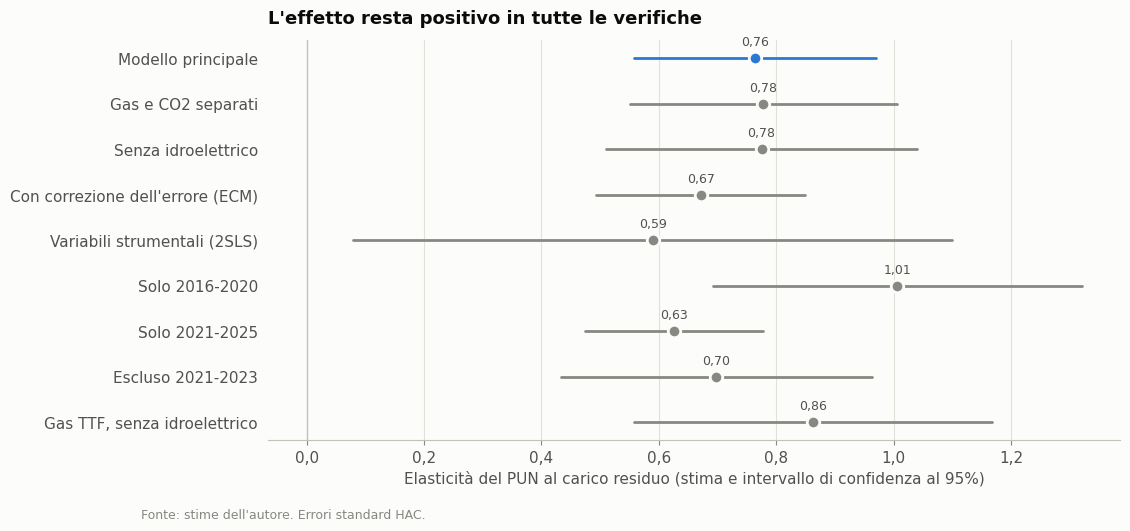

,Stima,"IC 2,5%","IC 97,5%"
Modello principale,0.76,0.56,0.97
Gas e CO2 separati,0.78,0.55,1.01
Senza idroelettrico,0.78,0.51,1.04
Con correzione dell'errore (ECM),0.67,0.49,0.85
Variabili strumentali (2SLS),0.59,0.08,1.10
Solo 2016-2020,1.01,0.69,1.32
Solo 2021-2025,0.63,0.47,0.78
Escluso 2021-2023,0.70,0.43,0.96
"Gas TTF, senza idroelettrico",0.86,0.56,1.17


In [35]:
# Elasticità al carico residuo in tutte le specificazioni (grafico di sintesi)
def riga(mod, v="dlog_Residual_Load"):
    a, b = mod.conf_int().loc[v]
    return mod.params[v], a, b


sintesi_rl = {
    "Modello principale": riga(modello),
    "Gas e CO2 separati": riga(modello_sep),
    "Senza idroelettrico": riga(m.stima_ols_hac(df, "dlog_PUN", regressori_senza_idro)),
    "Con correzione dell'errore (ECM)": riga(modello_ecm),
    "Variabili strumentali (2SLS)": (beta_rl_iv, lo_iv, hi_iv),
    "Solo 2016-2020": riga(m.stima_ols_hac(df[periodi["2016-2020"]], "dlog_PUN", regressori_base)),
    "Solo 2021-2025": riga(m.stima_ols_hac(df[periodi["2021-2025"]], "dlog_PUN", regressori_base)),
    "Escluso 2021-2023": riga(m.stima_ols_hac(df[periodi["Escluso 2021-2023"]], "dlog_PUN", regressori_base)),
    "Gas TTF, senza idroelettrico": riga(m.stima_ols_hac(df_ttf, "dlog_PUN", regressori_senza_idro)),
}
tab_rl = pd.DataFrame(sintesi_rl, index=["Stima", "IC 2,5%", "IC 97,5%"]).T

fig, ax = plt.subplots(figsize=(11, 5.2))
posizioni = np.arange(len(tab_rl))[::-1]
colori = [g.BLU] + [g.GRIGIO] * (len(tab_rl) - 1)
for yi, (nome, r), c in zip(posizioni, tab_rl.iterrows(), colori):
    ax.plot([r["IC 2,5%"], r["IC 97,5%"]], [yi, yi], color=c, lw=2, solid_capstyle="round")
    ax.plot(r["Stima"], yi, "o", color=c, ms=9, markeredgecolor=g.SFONDO, markeredgewidth=2)
    ax.annotate(f"{r['Stima']:.2f}".replace(".", ","), (r["Stima"], yi), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=g.TESTO_SECONDARIO)
ax.axvline(0, color=g.ASSE, lw=1)
ax.set_yticks(posizioni, tab_rl.index)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Elasticità del PUN al carico residuo (stima e intervallo di confidenza al 95%)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.1f}".replace(".", ","))
ax.set_title("L'effetto resta positivo in tutte le verifiche")
g.fonte(fig, "stime dell'autore. Errori standard HAC.")
g.salva(fig, "robustezza.png")
plt.show()
tab_rl.round(2)

In [36]:
b_sol, b_win = modello_dec.params["dlog_Solar"], modello_dec.params["dlog_Wind"]
p_sol, p_win = modello_dec.pvalues["dlog_Solar"], modello_dec.pvalues["dlog_Wind"]
r_lo, r_pt, r_hi = (sintesi.loc[k] for k in ["IC 2,5%", "Stima puntuale", "IC 97,5%"])
alt_ttf = tab_gas.iloc[0]

risultati = pd.Series({
    "Elasticità al costo marginale CCGT":
        f"{beta_mc:.2f} (p {p_fmt(modello.pvalues['dlog_MC_CCGT'])})",
    "Elasticità al carico residuo":
        f"{beta_rl:.2f} (IC 95%: {lo:.2f} - {hi:.2f})",
    "R² del modello base": f"{modello.rsquared:.2f}",
    "Riduzione media del PUN dovuta a solare + eolico (€/MWh)":
        f"{r_pt['Risparmio medio (€/MWh)']:.1f} (IC: {r_lo['Risparmio medio (€/MWh)']:.1f} - {r_hi['Risparmio medio (€/MWh)']:.1f})",
    "Volume cumulato nov 2016 - nov 2025 (mld €)":
        f"{r_pt['Risparmio totale (mld €)']:.1f} (IC: {r_lo['Risparmio totale (mld €)']:.1f} - {r_hi['Risparmio totale (mld €)']:.1f})",
    "Elasticità a solare + eolico (stima diretta)":
        f"{b_vre:.2f} (p {p_fmt(modello_vre.pvalues['dlog_VRE'])})",
    "Solare / eolico separati":
        f"{b_sol:.2f} (p {p_fmt(p_sol)}) / {b_win:.2f} (p {p_fmt(p_win)}); congiuntamente p {p_fmt(float(wald.pvalue))}",
    "Robustezza - elasticità al carico residuo 2016-2020 / 2021-2025":
        f"{b_rl_pre:.2f} / {b_rl_post:.2f} (differenza: p {p_fmt(p_rottura)})",
    "Robustezza - volume con elasticità per periodo (mld €)":
        f"{tab_scenari.loc['VRE = 0, elasticità per periodo', 'Risparmio totale (mld €)']:.1f}",
    "Robustezza - volume dovuto alla crescita delle VRE dal 2016 (mld €)":
        f"{tab_scenari.loc['Quota VRE ferma al 2016', 'Risparmio totale (mld €)']:.1f}",
    "Robustezza - gas e CO2 separati: quota del gas stimata / osservata":
        f"{quota_stimata:.2f} / {w_media:.2f} (uguaglianza: p {p_fmt(p_quota)})",
    "Robustezza - elasticità al carico residuo 2SLS (CDD + giorni lavorativi)":
        f"{beta_rl_iv:.2f} (IC 95%: {lo_iv:.2f} - {hi_iv:.2f}); Hausman p {p_fmt(p_hausman)}",
    "Robustezza - ECM: elasticità di breve periodo al carico residuo; termine di correzione":
        f"{beta_rl_ecm:.2f} (IC 95%: {lo_ecm:.2f} - {hi_ecm:.2f}); {gamma_ecm:.2f} (p {p_fmt(p_gamma)})",
    "Robustezza - lungo periodo (DOLS): elasticità al costo marginale / al carico residuo":
        f"{mc_lp:.2f} / {beta_rl_lp:.2f} (IC 95%: {lo_lp:.2f} - {hi_lp:.2f})",
    "Confronto - gas TTF, senza idroelettrico (feb 2016 - nov 2025)":
        f"elasticità al carico residuo {alt_ttf['beta RL']:.2f}, R² {alt_ttf['R2']:.2f}, volume {alt_ttf['Risparmio totale (mld €)']:.1f} mld €",
}, name="Stima")
risultati.to_frame()

,Stima
Elasticità al costo marginale CCGT,0.93 (p < 0.001)
Elasticità al carico residuo,0.76 (IC 95%: 0.56 - 0.97)
R² del modello base,0.92
Riduzione media del PUN dovuta a solare + eolico (€/MWh),16.0 (IC: 11.4 - 20.8)
Volume cumulato nov 2016 - nov 2025 (mld €),44.4 (IC: 31.7 - 57.5)
Elasticità a solare + eolico (stima diretta),-0.20 (p < 0.001)
Solare / eolico separati,-0.11 (p = 0.002) / -0.07 (p < 0.001); congiuntamente p < 0.001
Robustezza - elasticità al carico residuo 2016-2020 / 2021-2025,0.98 / 0.70 (differenza: p < 0.001)
Robustezza - volume con elasticità per periodo (mld €),43.3
Robustezza - volume dovuto alla crescita delle VRE dal 2016 (mld €),10.6


## 12. Conclusioni e limiti

**Risultati**

1. Il PUN è guidato in primo luogo dal **costo marginale della CCGT**, con un'elasticità vicina a 1 e fortemente significativa. La misura giusta del costo del gas è il prezzo spot italiano (PSV): spiega il PUN molto meglio del TTF a termine.
2. Il **carico residuo** ha un effetto positivo e significativo: più solare ed eolico, a parità di domanda, riducono il prezzo (*Merit Order Effect*). Il risultato regge su sotto-periodi diversi, anche se l'entità varia.
3. Il controfattuale *add-back* indica una riduzione del prezzo all'ingrosso il cui volume cumulato è nell'ordine di **decine di miliardi di euro** nel periodo rispetto a uno scenario senza VRE (sezioni 7 e 11). È un effetto lordo, **di breve periodo** e un ordine di grandezza. La sola **crescita** delle VRE dal 2016 vale circa un quarto di quel volume (sezione 7.1).
4. **Solare ed eolico** riducono entrambi il prezzo in modo significativo (sezione 9). La stima del solare è più fragile, perché la sua variazione mensile è in gran parte stagionale.
5. PUN e costo marginale sono **cointegrati**: nel lungo periodo il prezzo del gas passa quasi interamente nel PUN. L'effetto di lungo periodo del carico residuo sul livello del PUN, invece, non è identificato (sezione 10.5).

**Limiti affrontati**

| Limite | Verifica | Esito |
|---|---|---|
| Prezzo del gas a termine (TTF) per un prezzo elettrico spot | PSV spot del GME come prezzo principale (10.3) | Il PSV domina il TTF; elasticità al carico residuo e volume più bassi, stima più precisa |
| Idroelettrico omesso | Controllo nel modello (6, 10.3) | Molto significativo; non cambia l'elasticità al carico residuo ma ne aumenta la precisione |
| Parametri tecnici della CCGT ($\eta$, $EF$) fissi e ipotizzati | Gas e CO2 stimati separatamente (10.2) | La quota del gas stimata è compatibile con quella implicita nei parametri; $\eta$ non incide sulle stime |
| Un'unica elasticità per tutto il periodo | Interazione con il periodo 2021-2025 (7.1, 10.1) | L'elasticità è più bassa dal 2021, ma il volume cumulato cambia poco |
| Scenario estremo (VRE = 0) | Quota di VRE ferma al 2016 (7.1) | Volume più piccolo, con molta meno estrapolazione |
| Domanda endogena al prezzo | 2SLS con gradi-giorno di raffrescamento e giorni lavorativi (10.4) | Stima più bassa ma non statisticamente diversa; Hausman non rifiuta l'esogeneità |
| Idroelettrico come possibile *bad control* | Modello con PSV senza idroelettrico (10.3) | Elasticità al carico residuo e volume praticamente invariati |
| Variabili cointegrate in un modello solo in differenze | Test di cointegrazione, ECM e DOLS (10.5) | Termine di correzione significativo; l'elasticità di breve periodo resta significativa e di poco più bassa |

**Limiti che restano**

* Con dati mensili si perde la **dinamica oraria**, dove il Merit Order Effect agisce davvero. Un modello orario con le previsioni day-ahead di domanda, solare ed eolico darebbe stime più precise, soprattutto per il solare.
* Il controfattuale **non modella le risposte del sistema**: importazioni, idroelettrico, investimenti. Servirebbe un modello di dispacciamento del parco elettrico.
* L'**effetto di lungo periodo** delle rinnovabili sul livello del PUN non è identificato: l'elasticità di lungo periodo stimata con DOLS è piccola e non significativa. Il volume del controfattuale è un effetto di breve periodo, a sistema dato.
* La stima IV si basa sull'**ipotesi di esclusione** degli strumenti, che i test di sovraidentificazione non rifiutano ma non possono dimostrare. È anche molto meno precisa della stima OLS.
* L'idroelettrico a bacino è in parte **endogeno** al prezzo: per questo è usato solo come controllo.
* La serie PSV del GME parte da ottobre 2016, quindi il modello principale non copre i primi dieci mesi del 2016.
* La **domanda Ember** (produzione + saldo estero) è definita in modo diverso dalla "richiesta" pubblicata da Terna: il volume in euro dipende da questa scelta, le elasticità no.
* Con 109 osservazioni mensili le stime per sotto-periodo sono poco precise.
* Alcune **scelte di specificazione** (prezzo PSV, controllo per l'idroelettrico, insieme degli strumenti) sono state fatte dopo aver visto i dati. Sono motivate da test espliciti e il percorso è riportato per intero (tabella della sezione 10.3, confronto degli strumenti nella 10.4), ma i p-value non tengono conto di questa selezione.